In [3]:
import wrds
db = wrds.Connection(wrds_username="chengzhe")

Enter your WRDS username [chengzhe]: chengzhe
Enter your password: ········


WRDS recommends setting up a .pgpass file.


Create .pgpass file now [y/n]?:  y


Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done


In [4]:
tables = db.list_tables(library="crsp")
print([t for t in tables if "dsf" in t or "stocknames" in t])

['dsf', 'dsf62', 'dsf62_v2', 'dsf_v2', 'dsfhdr', 'dsfhdr62', 'stocknames', 'stocknames62', 'stocknames62_v2', 'stocknames_v2', 'wrds_dsf62v2_query', 'wrds_dsfv2_query']


In [5]:
print(db.raw_sql("select max(date) as last_date from crsp.dsf"))
print(db.raw_sql("select max(dlycaldt) as last_date from crsp.dsf_v2"))

    last_date
0  2024-12-31
    last_date
0  2025-12-31


In [6]:
db.describe_table(library="crsp", table="stocknames_v2")

Approximately 86060 rows in crsp.stocknames_v2.


,name,nullable,type,comment
0,permno,True,INTEGER,PERMNO
1,permco,True,INTEGER,PERMCO
2,namedt,True,DATE,Security Information Start Date
3,nameenddt,True,DATE,Security Information End Date
4,securitybegdt,True,DATE,Begin Date of Stock Data
5,securityenddt,True,DATE,End Date of Stock Data
6,hdrcusip,True,VARCHAR(8),Header CUSIP -8 Characters
7,hdrcusip9,True,VARCHAR(9),Header CUSIP -9 Characters
8,cusip,True,VARCHAR(8),CUSIP
9,cusip9,True,VARCHAR(9),CUSIP9


In [7]:
import os
import pandas as pd

names = db.raw_sql("""
    select permno, issuernm, ticker, namedt, nameenddt,
           primaryexch, securitytype, securitysubtype
    from crsp.stocknames_v2
""", date_cols=["namedt", "nameenddt"])

os.makedirs("../data/crsp", exist_ok=True)
names.to_csv("../data/crsp/stocknames_v2.csv", index=False)
print(len(names), "rows saved")

names[names["issuernm"].str.contains("CRINETICS", case=False, na=False)]

87839 rows saved


,permno,issuernm,ticker,namedt,nameenddt,primaryexch,securitytype,securitysubtype
16318,17959,CRINETICS PHARMACEUTICALS INC,CRNX,2018-07-18,2025-12-31,Q,EQTY,COM


In [8]:
print(names["securitytype"].value_counts())
print(names["primaryexch"].value_counts())

securitytype
EQTY    74779
FUND    12979
DERV       81
Name: count, dtype: int64[pyarrow]
primaryexch
Q    44714
N    23296
A    10639
R     5460
X     1952
B     1777
I        1
Name: count, dtype: int64[pyarrow]


In [9]:
import re, difflib
import numpy as np

review = pd.read_csv("../data/processed/review_sheet.csv", parse_dates=["FDA Approval Date"])

SUFFIXES = r"\b(inc|incorporated|corp|corporation|co|company|ltd|limited|llc|lp|plc|sa|ag|nv|bv|se|ab|as|gmbh|spa|dac|sas|usa|us|holdings?|group|ireland|the)\b"
def norm(name):
    s = re.sub(r"[^a-z0-9 ]", " ", str(name).lower())
    s = re.sub(SUFFIXES, " ", s)
    return re.sub(r"\s+", " ", s).strip()

eq = names[(names["securitytype"] == "EQTY") & names["primaryexch"].isin(["N", "Q", "A"])].copy()
eq["nameenddt"] = eq["nameenddt"].fillna(pd.Timestamp("2099-12-31"))
eq["norm"] = eq["issuernm"].apply(norm)
eq["first"] = eq["norm"].str.split().str[0]

def match_crsp(applicant, date):
    n = norm(applicant)
    if not n:
        return np.nan, np.nan, np.nan, ""
    live = eq[(eq["namedt"] <= date) & (eq["nameenddt"] >= date)]   # names in use on the approval date
    exact = live[live["norm"] == n]
    if len(exact):
        r = exact.iloc[0]
        return r["permno"], r["ticker"], r["issuernm"], "exact"
    same_first = live[live["first"] == n.split()[0]]
    if len(same_first):
        scores = same_first["norm"].apply(lambda c: difflib.SequenceMatcher(None, n, c).ratio())
        best = scores.idxmax()
        if scores[best] >= 0.6:
            r = same_first.loc[best]
            return r["permno"], r["ticker"], r["issuernm"], f"fuzzy {scores[best]:.2f}"
    return np.nan, np.nan, np.nan, ""

m = review.apply(lambda r: match_crsp(r["Applicant"], r["FDA Approval Date"]), axis=1)
review[["permno", "crsp_ticker", "crsp_name", "match_type"]] = pd.DataFrame(m.tolist(), index=review.index)
print("Matched:", review["permno"].notna().sum(), "of", len(review))

review.loc[review["match_type"].str.startswith("fuzzy"),
           ["Applicant", "crsp_name", "crsp_ticker", "match_type"]]

Matched: 156 of 226


,Applicant,crsp_name,crsp_ticker,match_type
28,Iterum Therapeutics U.S. Ltd.,ITERUM THERAPEUTICS PLC,ITRM,fuzzy 0.90
32,Ascendis Pharma Bone Diseases A/S,ASCENDIS PHARMA A S,ASND,fuzzy 0.73
41,"BeiGene U.S.A., Inc.",BEIGENE LTD,BGNE,fuzzy 0.70
57,"Bausch and Lomb, Inc.",BAUSCH & LOMB CORP,BLCO,fuzzy 0.85
58,Pharming Technologies B.V.,PHARMING GROUP N V,PHAR,fuzzy 0.65
95,Ascendis Pharma Endocrinology Division A/S,ASCENDIS PHARMA A S,ASND,fuzzy 0.62
97,Albireo AB,ALBIREO PHARMA INC,ALBO,fuzzy 0.67
111,"Origin Biosciences, Inc.",ORIGIN BANCORP INC,OBNK,fuzzy 0.62
129,"MorphoSys US, Inc.",MORPHOSYS A G,MOR,fuzzy 0.82
130,Dr. Reddy’s Laboratories,DR REDDYS LABORATORIES LTD,RDY,fuzzy 0.98


In [10]:
# Reject the bad fuzzy match (a bank, not the drug company)
bad = review["Applicant"].str.startswith("Origin Biosciences")
review.loc[bad, ["permno", "crsp_ticker", "crsp_name"]] = np.nan
review.loc[bad, "match_type"] = "rejected: wrong company"

unmatched = sorted(review.loc[review["permno"].isna(), "Applicant"].unique())
print(len(unmatched), "unmatched applicants")
print(unmatched)

69 unmatched applicants
['ADC Therapeutics S.A.', 'AMAG Pharmaceuticals', 'Ablynx NV', 'Actelion Pharmaceuticals', 'Advanced Accelerator Applications USA, Inc.', 'Allecra Therapeutics SAS', 'Altor BioScience, LLC', 'Amryt Pharmaceuticals DAC', 'Anacor Pharmacueticals', 'Ardea Biosciences', 'Ariad Pharmaceuticals', 'Asklepion Pharmaceuticals', 'Astex Pharmaceuticals, Inc.', 'Aveo Pharmaceuticals, Inc.', 'Avid Radiopharmaceuticals, Inc.', 'Bausch & Lomb', 'Bioverativ USA, Inc.', 'Braintree Laboratories, Inc.', 'CTI BioPharma Corporation', 'Checkpoint Therapeutics, Inc.', 'Chimerix, Inc.', 'Commave Therapeutics SA', 'CymaBay Therapeutics, Inc.', 'Deciphera Pharmaceuticals, LLC', 'Dermavant Sciences, Inc.', 'Dyax Corporation', 'Elusys Therapeutics', 'Entasis Therapeutics Inc.', 'Entasis Therapeutics, Inc.', 'Fabre-Kramer Pharmaceuticals, Inc.', 'Forma Therapeutics, Inc.', 'Furiex Pharmaceuticals', 'GW Pharmaceuticals', 'Giskit B.V.', 'IVERIC Bio, Inc.', 'Kadmon Pharmaceuticals, LLC', 'LIB 

In [11]:
# Hand-checked tickers for applicants the name match missed.
# For subsidiaries, the parent company's ticker. Tried in order;
# the first ticker in use on the approval date wins.
MANUAL_TICKERS = {
    "ADC Therapeutics": ["ADCT"], "AMAG": ["AMAG"], "Aveo": ["AVEO"],
    "Altor BioScience": ["IBRX"], "Bausch & Lomb": ["BLCO", "BHC", "VRX"],
    "CTI BioPharma": ["CTIC"], "Checkpoint Therapeutics": ["CKPT"],
    "Chimerix": ["CMRX", "JAZZ"], "Dermavant": ["ROIV"], "Entasis": ["INVA"],
    "GW Pharmaceuticals": ["GWPH"], "Kadmon": ["KDMN"], "LNHC": ["LGND"],
    "Loxo Oncology": ["LOXO"], "Mallinckrodt": ["MNK"], "Melinta": ["MLNT"],
    "NPS Pharmaceuticals": ["NPSP"], "Origin Biosciences": ["BBIO"],
    "QED Therapeutics": ["BBIO"], "PTC Therapeutics": ["PTCT"],
    "Phathom": ["PHAT"], "Progenics": ["PGNX", "LNTH"], "SIGA": ["SIGA"],
    "Stemline": ["STML"], "TG Therapeutics": ["TGTX"], "Zevra": ["ZVRA"],
}

def match_ticker(tickers, date):
    for t in tickers:
        hit = eq[(eq["ticker"] == t) & (eq["namedt"] <= date) & (eq["nameenddt"] >= date)]
        if len(hit):
            r = hit.iloc[0]
            return r["permno"], r["ticker"], r["issuernm"], f"manual: {t}"
    return np.nan, np.nan, np.nan, "no US-listed stock at approval"

for i, r in review[review["permno"].isna()].iterrows():
    key = next((k for k in MANUAL_TICKERS if r["Applicant"].startswith(k)), None)
    if key:
        review.loc[i, ["permno", "crsp_ticker", "crsp_name", "match_type"]] = \
            match_ticker(MANUAL_TICKERS[key], r["FDA Approval Date"])
    elif review.loc[i, "match_type"] == "":
        review.loc[i, "match_type"] = "no US-listed stock at approval"

print("Matched:", review["permno"].notna().sum(), "of", len(review))
review.loc[review["match_type"].str.startswith("manual") |
           review["Applicant"].str.startswith(tuple(MANUAL_TICKERS)),
           ["Proprietary Name", "Applicant", "FDA Approval Date", "crsp_name", "crsp_ticker", "match_type"]]

Matched: 179 of 226


,Proprietary Name,Applicant,FDA Approval Date,crsp_name,crsp_ticker,match_type
3,Nuzolvence,Entasis Therapeutics Inc.,2025-12-12,THERAVANCE INC,INVA,manual: INVA
12,Modeyso,"Chimerix, Inc.",2025-08-06,JAZZ PHARMACEUTICALS PLC,JAZZ,manual: JAZZ
14,Sephience,"PTC Therapeutics, Inc.",2025-07-28,P T C THERAPEUTICS INC,PTCT,manual: PTCT
22,Unloxcyt,"Checkpoint Therapeutics, Inc.",2024-12-13,CHECKPIONT THERAPEUTICS INC,CKPT,manual: CKPT
29,Miplyffa,Zevra Denmark A/S,2024-09-20,ZEVRA THERAPEUTICS INC,ZVRA,manual: ZVRA
37,Anktiva,"Altor BioScience, LLC",2024-04-22,IMMUNITYBIO INC,IBRX,manual: IBRX
43,Zelsuvmi,"LNHC, Inc.",2024-01-05,LIGAND PHARMACEUTICALS INC,LGND,manual: LGND
56,Xacduro,"Entasis Therapeutics, Inc.",2023-05-23,THERAVANCE INC,INVA,manual: INVA
64,Orserdu,"Stemline Therapeutics, Inc.",2023-01-27,NaN,NaN,no US-listed stock at approval
65,Jaypirca,"Loxo Oncology, Inc.",2023-01-27,NaN,NaN,no US-listed stock at approval


In [12]:
review.to_csv("../data/crsp/review_crsp_matched.csv", index=False)
print(review["match_type"].str.split(":").str[0].value_counts())

match_type
exact                             136
no US-listed stock at approval     47
manual                             24
fuzzy 0.98                          5
fuzzy 0.90                          2
fuzzy 0.84                          2
fuzzy 0.73                          1
fuzzy 0.70                          1
fuzzy 0.85                          1
fuzzy 0.65                          1
fuzzy 0.62                          1
fuzzy 0.67                          1
fuzzy 0.82                          1
fuzzy 0.74                          1
fuzzy 0.91                          1
fuzzy 0.96                          1
Name: count, dtype: int64


In [13]:
db.describe_table(library="crsp", table="dsf_v2")

Approximately 110257376 rows in crsp.dsf_v2.


,name,nullable,type,comment
0,permno,True,INTEGER,PERMNO
1,hdrcusip,True,VARCHAR(8),Header CUSIP -8 Characters
2,permco,True,INTEGER,PERMCO
3,siccd,True,INTEGER,Sic Code
4,nasdissuno,True,INTEGER,Nasdaq Issue Number
5,yyyymmdd,True,INTEGER,YYYYMMDD - Daily Calendar Period Key
6,sharetype,True,VARCHAR(3),Share Type
7,securitytype,True,VARCHAR(4),Security Type
8,securitysubtype,True,VARCHAR(3),Security Sub-Type
9,usincflg,True,VARCHAR(1),US Incorporation Flag


In [14]:
cols = db.describe_table(library="crsp", table="dsf_v2")["name"].tolist()
print([c for c in cols if "ret" in c or "shr" in c])

db.raw_sql("""
    select permno, dlycaldt, dlyprc, dlycap, dlyret
    from crsp.dsf_v2
    where permno = 17959 and dlycaldt between '2025-09-22' and '2025-10-03'
    order by dlycaldt
""")

Approximately 110257376 rows in crsp.dsf_v2.
['sharetype', 'dlyret', 'dlyretx', 'dlyreti', 'dlyretmissflg', 'dlyretdurflg', 'dlydistretflg', 'dlycumfacshr', 'shrout']


,permno,dlycaldt,dlyprc,dlycap,dlyret
0,17959,2025-09-22,33.72,3175614.72,-0.005603
1,17959,2025-09-23,35.86,3377151.36,0.063464
2,17959,2025-09-24,35.18,3313111.68,-0.018963
3,17959,2025-09-25,35.89,3379976.64,0.020182
4,17959,2025-09-26,45.91,4323620.16,0.279186
5,17959,2025-09-29,43.51,4097597.76,-0.052276
6,17959,2025-09-30,41.65,3937924.2,-0.042749
7,17959,2025-10-01,41.61,3934142.28,-0.00096
8,17959,2025-10-02,41.51,3924687.48,-0.002403
9,17959,2025-10-03,40.86,3863231.28,-0.015659


In [15]:
spy_rows = names[(names["ticker"] == "SPY") & (names["securitytype"] == "FUND")]
print(spy_rows[["permno", "issuernm", "namedt", "nameenddt"]])
spy_permno = int(spy_rows["permno"].iloc[0])

permnos = review["permno"].dropna().astype(int).unique().tolist() + [spy_permno]
print(len(permnos), "PERMNOs to download")

rets = db.raw_sql(f"""
    select permno, dlycaldt as date, dlyret as ret, dlycap as mcap_k
    from crsp.dsf_v2
    where permno in ({",".join(map(str, permnos))})
      and dlycaldt between '2013-06-01' and '2025-12-31'
""", date_cols=["date"])

rets.to_csv("../data/crsp/daily_returns.csv", index=False)
print(rets.shape, "rows x columns")
print(rets["permno"].nunique(), "PERMNOs with data")

       permno                    issuernm     namedt  nameenddt
70121   84398                  SPDR TRUST 1993-01-29 2009-02-23
70122   84398                  SPDR TRUST 2009-02-24 2010-01-26
70123   84398  SPDR S & P 500 E T F TRUST 2010-01-27 2025-12-31
139 PERMNOs to download
(321922, 4) rows x columns
139 PERMNOs with data


In [17]:
rets = rets.sort_values(["permno", "date"])
tdays = pd.DatetimeIndex(sorted(rets.loc[rets["permno"] == spy_permno, "date"].unique()))

manual = pd.read_csv("../data/processed/review_sheet_manual.csv", parse_dates=["FDA Approval Date"])
manual["event_day0"] = pd.to_datetime(manual["event_day0"], errors="coerce")
ev = review.drop(columns=["event_day0", "include", "exclude_reason"], errors="ignore").merge(
    manual[["Proprietary Name", "FDA Approval Date", "event_day0", "include", "exclude_reason"]],
    on=["Proprietary Name", "FDA Approval Date"], how="left")

ev["day0"] = ev["event_day0"].fillna(ev["FDA Approval Date"])
idx = tdays.searchsorted(ev["day0"]).clip(max=len(tdays) - 1)   # first trading day on/after
ev["day0"] = tdays[idx]

by_permno = {p: g.set_index("date") for p, g in rets.groupby("permno")}

def crsp_checks(row):
    g = by_permno.get(row["permno"]) if pd.notna(row["permno"]) else None
    if g is None:
        return pd.Series([np.nan, 0, 0])
    before = g[g.index < row["day0"]]
    after = g[g.index >= row["day0"]]
    mcap = before["mcap_k"].iloc[-1] / 1000 if len(before) else np.nan   # thousands -> millions
    return pd.Series([mcap, len(before), len(after)])

ev[["mcap_m_dm1", "days_before", "days_after"]] = ev.apply(crsp_checks, axis=1)

def status(r):
    if r["include"] == "N" and "confound" in str(r["exclude_reason"]):
        return "exclude: confounding event (hand-checked)"
    if pd.isna(r["permno"]):
        return "exclude: " + r["match_type"]
    if r["days_before"] < 250:
        return "exclude: under 250 days of history"
    if r["days_after"] < 6:
        return "exclude: CRSP data ends before day +5"
    if pd.isna(r["mcap_m_dm1"]):
        return "review: no market cap"
    if r["mcap_m_dm1"] < 300:
        return "exclude: market cap < $300M"
    if r["mcap_m_dm1"] > 10000:
        return "exclude: market cap > $10B"
    return "candidate"

ev["status"] = ev.apply(status, axis=1)
ev.to_csv("../data/crsp/events_screened.csv", index=False)
print(ev["status"].value_counts())

status
candidate                                    131
exclude: no US-listed stock at approval       47
exclude: market cap < $300M                   22
exclude: market cap > $10B                    14
exclude: under 250 days of history             8
exclude: confounding event (hand-checked)      3
exclude: CRSP data ends before day +5          1
Name: count, dtype: int64


In [18]:
cand = ev[ev["status"] == "candidate"]
perm_list = ",".join(str(int(p)) for p in cand["permno"].unique())

links = db.raw_sql(f"""
    select l.lpermno as permno, c.cik, c.conm
    from crsp.ccmxpf_lnkhist l
    join comp.company c on l.gvkey = c.gvkey
    where l.lpermno in ({perm_list})
      and l.linktype in ('LU', 'LC')
""")
links = links.dropna(subset=["cik"]).drop_duplicates("permno")
print(len(links), "of", cand["permno"].nunique(), "candidate PERMNOs have a CIK")
links.head()

102 of 102 candidate PERMNOs have a CIK


,permno,cik,conm
0,12919.0,0001492426,HORIZON THERAPEUTICS PUB LTD
1,13107.0,0001466301,CLOVIS ONCOLOGY INC
2,13167.0,0001347613,SYNERGY PHARMACEUTICALS INC
3,13202.0,0001526119,VERASTEM INC
4,13262.0,0001340652,CHEMOCENTRYX INC


In [19]:
import json, time, requests
from pathlib import Path

SEC_HEADERS = {"User-Agent": "Chengzhe Jiang chengzhe@berkeley.edu"}
CACHE = Path("../data/cache")
CACHE.mkdir(parents=True, exist_ok=True)

def sec_get_json(url, cache_name):
    path = CACHE / cache_name
    if path.exists():
        return json.loads(path.read_text())
    r = requests.get(url, headers=SEC_HEADERS, timeout=60)
    r.raise_for_status()
    path.write_text(r.text)
    time.sleep(0.15)
    return r.json()

def load_filings(cik):
    cik10 = str(int(cik)).zfill(10)
    sub = sec_get_json(f"https://data.sec.gov/submissions/CIK{cik10}.json", f"sub_{cik10}.json")
    frames = [pd.DataFrame(sub["filings"]["recent"])]
    for f in sub["filings"].get("files", []):
        frames.append(pd.DataFrame(sec_get_json(f"https://data.sec.gov/submissions/{f['name']}", f["name"])))
    df = pd.concat(frames, ignore_index=True).reindex(columns=["form", "filingDate", "items"])
    df["filingDate"] = pd.to_datetime(df["filingDate"])
    return df

cik_of = dict(zip(links["permno"], links["cik"]))
filings = {}
for p, cik in cik_of.items():
    try:
        filings[p] = load_filings(cik)
    except Exception as e:
        print("failed", p, cik, e)
print(len(filings), "companies' filings loaded")

102 companies' filings loaded


In [20]:
FLAG_ITEMS = {"2.02": "earnings", "1.01": "material agreement", "2.01": "acquisition",
              "3.02": "equity sale", "5.02": "exec change"}
OFFERING_FORMS = ("424B4", "424B5", "424B7")

def edgar_flags(permno, day0):
    f = filings.get(permno)
    if f is None:
        return "no filings"
    i = tdays.searchsorted(day0)
    lo, hi = tdays[max(i - 5, 0)], tdays[min(i + 5, len(tdays) - 1)]
    w = f[(f["filingDate"] >= lo) & (f["filingDate"] <= hi)]
    flags = []
    for _, r in w.iterrows():
        form = str(r["form"])
        if form.startswith("8-K"):
            hits = [FLAG_ITEMS[x.strip()] for x in str(r["items"]).split(",") if x.strip() in FLAG_ITEMS]
            if hits:
                flags.append(f"{r['filingDate'].date()} 8-K ({', '.join(hits)})")
        elif form.startswith(OFFERING_FORMS):
            flags.append(f"{r['filingDate'].date()} {form} (possible offering)")
    return "; ".join(flags)

mask = ev["status"] == "candidate"
ev["edgar_flags"] = ""
ev.loc[mask, "edgar_flags"] = [edgar_flags(p, d) for p, d in zip(ev.loc[mask, "permno"], ev.loc[mask, "day0"])]
flagged = mask & (ev["edgar_flags"] != "")
print(flagged.sum(), "of", mask.sum(), "candidates have filings to review")

50 of 131 candidates have filings to review


In [21]:
pd.set_option("display.max_colwidth", 200)

types = (ev.loc[flagged, "edgar_flags"]
           .str.findall(r"\(([^)]*)\)")
           .explode()
           .str.split(", ")
           .explode())
print(types.value_counts())

ev.loc[flagged, ["Proprietary Name", "crsp_ticker", "day0", "edgar_flags"]].sort_values("day0")

edgar_flags
earnings              22
material agreement    21
possible offering     19
exec change           12
equity sale            2
acquisition            2
Name: count, dtype: int64


,Proprietary Name,crsp_ticker,day0,edgar_flags
211,Nuplazid,ACAD,2016-04-29,2016-05-05 8-K (earnings); 2016-05-03 8-K (exec change)
208,Exondys 51,SRPT,2016-09-19,2016-09-23 8-K (material agreement); 2016-09-23 424B5 (possible offering); 2016-09-21 424B5 (possible offering); 2016-09-21 8-K (exec change)
204,Siliq,VRX,2017-02-15,2017-02-13 8-K (material agreement)
203,Xermelo,LXRX,2017-02-28,2017-03-03 8-K (earnings)
198,Tymlos,RDUS,2017-04-28,2017-05-01 8-K (earnings)
191,Vyzulta,VRX,2017-11-02,2017-11-07 8-K (earnings); 2017-11-01 8-K (material agreement)
189,Rhopressa,AERI,2017-12-18,2017-12-19 424B5 (possible offering); 2017-12-19 8-K (material agreement)
184,Tavalisse,RIGL,2018-04-17,2018-04-20 8-K (earnings); 2018-04-20 424B5 (possible offering); 2018-04-18 424B5 (possible offering)
175,Galafold,FOLD,2018-08-10,2018-08-07 8-K (earnings)
174,Onpattro,ALNY,2018-08-10,2018-08-17 8-K (material agreement)


In [22]:
AUTO = {"earnings", "possible offering", "equity sale", "acquisition"}

def offset(day0, d):
    return int(tdays.searchsorted(d) - tdays.searchsorted(day0))   # trading days from day 0

def decide(r):
    if r["status"] != "candidate":
        return r["status"]
    if r["include"] == "Y":
        return "include (hand-checked)"
    if not r["edgar_flags"]:
        return "include"
    edge = False
    for item in r["edgar_flags"].split("; "):
        d = pd.Timestamp(item[:10])
        kinds = set(item[item.find("(") + 1 : -1].split(", "))
        if kinds & AUTO:
            k = offset(r["day0"], d)
            if abs(k) <= 4:
                return f"exclude: {', '.join(sorted(kinds & AUTO))} on day {k:+d}"
            edge = True
    return "review: confounder at day ±5" if edge else "review: read 8-K (agreement or exec change)"

ev["final"] = ev.apply(decide, axis=1)
print(ev["final"].str.split(":").str[0].value_counts())

ev.loc[ev["final"].str.startswith("review"),
       ["Proprietary Name", "crsp_ticker", "day0", "edgar_flags", "final"]].sort_values("day0")

final
exclude                   123
include                    77
review                     21
include (hand-checked)      5
Name: count, dtype: int64


,Proprietary Name,crsp_ticker,day0,edgar_flags,final
204,Siliq,VRX,2017-02-15,2017-02-13 8-K (material agreement),review: read 8-K (agreement or exec change)
174,Onpattro,ALNY,2018-08-10,2018-08-17 8-K (material agreement),review: read 8-K (agreement or exec change)
171,Copiktra,VSTM,2018-09-24,2018-09-25 8-K (material agreement),review: read 8-K (agreement or exec change)
170,Nuzyra,PRTK,2018-10-02,2018-10-04 8-K (exec change),review: read 8-K (agreement or exec change)
169,Tegsedi,IONS,2018-10-05,2018-10-10 8-K (material agreement),review: read 8-K (agreement or exec change)
158,Xpovio,KPTI,2019-07-03,2019-07-03 8-K (exec change),review: read 8-K (agreement or exec change)
151,Oxbryta,GBT,2019-11-25,2019-11-22 8-K (exec change),review: read 8-K (agreement or exec change)
150,Vyondys 53,SRPT,2019-12-12,2019-12-13 8-K (material agreement),review: read 8-K (agreement or exec change)
147,Tepezza,HZNP,2020-01-21,2020-01-24 8-K (exec change); 2020-01-13 8-K (earnings),review: confounder at day ±5
126,Gavreto,BPMC,2020-09-04,2020-09-01 8-K (exec change),review: read 8-K (agreement or exec change)


In [23]:
rev = ev[ev["final"].str.startswith("review")].copy()
rev["cik"] = rev["permno"].map(cik_of).astype(int)
rev["edgar"] = ("https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK="
                + rev["cik"].astype(str) + "&type=8-K&dateb="
                + (rev["day0"] + pd.Timedelta(days=15)).dt.strftime("%Y%m%d") + "&count=20")
for _, r in rev.sort_values("day0").iterrows():
    print(r["Proprietary Name"], "|", r["edgar_flags"])
    print("  ", r["edgar"])

Siliq | 2017-02-13 8-K (material agreement)
   https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=885590&type=8-K&dateb=20170302&count=20
Onpattro | 2018-08-17 8-K (material agreement)
   https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=1178670&type=8-K&dateb=20180825&count=20
Copiktra | 2018-09-25 8-K (material agreement)
   https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=1526119&type=8-K&dateb=20181009&count=20
Nuzyra | 2018-10-04 8-K (exec change)
   https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=1178711&type=8-K&dateb=20181017&count=20
Tegsedi | 2018-10-10 8-K (material agreement)
   https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=874015&type=8-K&dateb=20181020&count=20
Xpovio | 2019-07-03 8-K (exec change)
   https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=1503802&type=8-K&dateb=20190718&count=20
Oxbryta | 2019-11-22 8-K (exec change)
   https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany

In [27]:
REVIEW_DECISIONS = {
    "Tepezza":    ("N", "earnings at day -5"),
    "Orgovyx":    ("N", "Pfizer collaboration ($650M upfront) at day +5"),
    "Orladeyo":   ("N", "$325M Royalty Pharma/Athyrium financing at day +2"),
    "Copiktra":   ("N", "CSPC China license at day +1"),
    "Tegsedi":    ("N", "Roche collaboration on IONIS-FB-LRx at day +3"),
    "Bizengri":   ("N", "Partner Therapeutics US license at day -2"),
    "Siliq":      ("N", "litigation management agreement with Pershing Square at day -3"),
    "Vyondys 53": ("N", "new credit agreement at day +1"),
    "Wainua":     ("N", "Otsuka license agreement at day -3"),
    "Voquezna Triple Pak": ("N", "$260M revenue interest financing at day +1"),
    "Livmarli":   ("Y", "amendment to existing financing, filed with approval"),
    "Onpattro":   ("Y", "routine lease amendment"),
    "Ziihera":    ("Y", "routine amendment of undrawn revolver"),
    "Nuzyra":     ("Y", "employee incentive plan, not CEO/CFO"),
    "Tevimbra":   ("Y", "not a CEO/CFO change (CFO change came July 2024)"),
    "Gavreto":    ("Y", "President of R&D appointed, not CEO/CFO"),
    "Xpovio":     ("Y", "Chief Commercial Officer departure, not CEO/CFO"),
    "Oxbryta":    ("Y", "board member departure, not CEO/CFO"),
    "Tavneos":    ("Y", "Chief Medical Officer appointed, not CEO/CFO"),
    "Xdemvy":     ("Y", "offering announced 4:30 PM day +5 -> reaction day +6"),
    "Ogsiveo":    ("Y", "offering announced 4:13 PM day +5 -> reaction day +6"),
}

for name, (decision, reason) in REVIEW_DECISIONS.items():
    rows = ev["Proprietary Name"] == name
    ev.loc[rows, "final"] = ("include" if decision == "Y" else "exclude") + f" (reviewed): {reason}"

ev.to_csv("../data/crsp/events_final.csv", index=False)
print(ev["final"].str.split(":").str[0].str.split(" \\(").str[0].value_counts())
print(ev["final"].str.startswith("include").sum(), "events in the final sample")

final
exclude    133
include     93
Name: count, dtype: int64
93 events in the final sample


In [36]:
import statsmodels.api as sm

import warnings
warnings.filterwarnings("ignore")

rets["ret"] = pd.to_numeric(rets["ret"], errors="coerce")
by_permno = {p: g.set_index("date") for p, g in rets.groupby("permno")}
spy = by_permno[spy_permno]["ret"]

def event_study_crsp(permno, day0):
    df = (pd.concat([by_permno[permno]["ret"], spy], axis=1, keys=["stock", "mkt"])
            .dropna()
            .astype("float64"))
    pos = df.index.searchsorted(day0)
    if pos < 250 or pos + 5 >= len(df):
        return None

    est = df.iloc[pos - 250 : pos - 30]
    model = sm.OLS(est["stock"], sm.add_constant(est["mkt"])).fit()
    a, b = model.params["const"], model.params["mkt"]

    lo, hi = max(pos - 10, 0), min(pos + 11, len(df))
    win = df.iloc[lo:hi].copy()
    win["day"] = np.arange(lo, hi) - pos
    win["ar"] = win["stock"] - (a + b * win["mkt"])
    ar = win.set_index("day")["ar"]

    return {"beta": b, "alpha": a, "r2": model.rsquared,
            "car_m1_p1": ar.loc[-1:1].sum(), "car_0_p5": ar.loc[0:5].sum(),
            "ar_path": ar}

In [37]:
final = ev[ev["final"].str.startswith("include")].copy()

rows, paths = [], {}
for i, r in final.iterrows():
    res = event_study_crsp(r["permno"], r["day0"])
    if res is None:
        print("skipped:", r["Proprietary Name"])
        continue
    paths[r["Proprietary Name"]] = res.pop("ar_path")
    rows.append({"drug": r["Proprietary Name"], "ticker": r["crsp_ticker"],
                 "day0": r["day0"].date(), "mcap_m": float(r["mcap_m_dm1"]), **res})

results = pd.DataFrame(rows)
print(len(results), "events analyzed")
results.sort_values("day0", ascending=False).head(10).round(3)

93 events analyzed


,drug,ticker,day0,mcap_m,beta,alpha,r2,car_m1_p1,car_0_p5
0,Nuzolvence,INVA,2025-12-15,1542.484,0.130,-0.000,0.014,-0.032,-0.031
1,Redemplo,ARWR,2025-11-18,5448.435,1.715,0.003,0.219,-0.041,0.119
2,Komzifti,KURA,2025-11-13,929.352,0.900,-0.003,0.068,0.071,0.088
3,Palsonify,CRNX,2025-09-26,3379.977,1.178,-0.003,0.214,0.250,0.161
4,Dawnzera,IONS,2025-08-21,6823.529,0.875,-0.001,0.172,-0.001,-0.015
5,Sephience,PTCT,2025-07-28,3551.372,1.106,0.002,0.161,0.062,0.161
6,Ibtrozi,NUVB,2025-06-11,858.335,1.178,-0.001,0.117,-0.306,-0.296
7,Avmapki Fakzynja Co-Pack,VSTM,2025-05-08,367.388,1.177,0.001,0.018,0.082,0.114
8,Gomekli,SWTX,2025-02-11,4017.762,1.086,-0.002,0.082,0.437,0.030
9,Tryngolza,IONS,2024-12-19,5723.766,0.624,-0.001,0.046,-0.040,-0.012


In [38]:
from scipy import stats

for col, label in [("car_m1_p1", "CAR[-1,+1]"), ("car_0_p5", "CAR[0,+5]")]:
    x = results[col]
    t, p = stats.ttest_1samp(x, 0)
    w_p = stats.wilcoxon(x).pvalue
    print(f"{label}: mean {x.mean():.2%} | median {x.median():.2%} | "
          f"positive {(x > 0).mean():.0%} | t = {t:.2f}, p = {p:.3f} | "
          f"Wilcoxon p = {w_p:.3f} | n = {len(x)}")

results.to_csv("../data/crsp/event_results.csv", index=False)

CAR[-1,+1]: mean 8.04% | median 1.39% | positive 57% | t = 2.52, p = 0.013 | Wilcoxon p = 0.016 | n = 93
CAR[0,+5]: mean 9.54% | median 3.66% | positive 66% | t = 2.91, p = 0.005 | Wilcoxon p = 0.001 | n = 93


Matplotlib is building the font cache; this may take a moment.


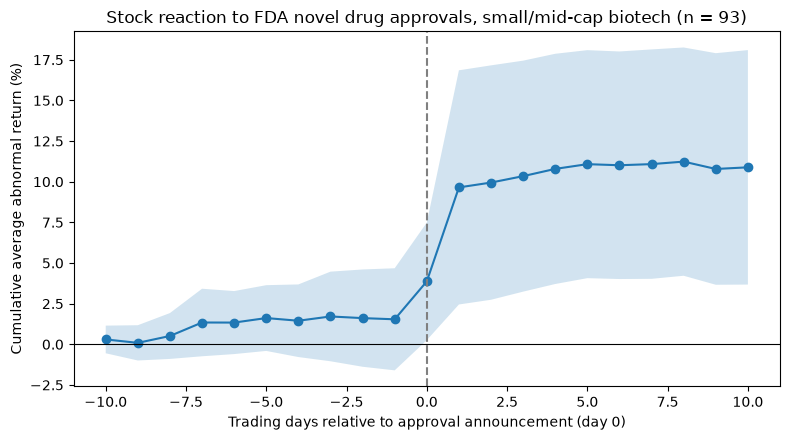

In [39]:
import matplotlib.pyplot as plt

ar = pd.DataFrame(paths)            # rows = event day, columns = events
cum = ar.cumsum()                   # each event's running total from day -10
caar = cum.mean(axis=1)             # average across events
se = cum.std(axis=1) / np.sqrt(cum.count(axis=1))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(caar.index, caar * 100, marker="o")
ax.fill_between(caar.index, (caar - 1.96 * se) * 100, (caar + 1.96 * se) * 100, alpha=0.2)
ax.axvline(0, linestyle="--", color="gray")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Trading days relative to approval announcement (day 0)",
       ylabel="Cumulative average abnormal return (%)",
       title=f"Stock reaction to FDA novel drug approvals, small/mid-cap biotech (n = {ar.shape[1]})")
fig.tight_layout()
fig.savefig("../figures/caar.png", dpi=200)
plt.show()

In [40]:
import statsmodels.formula.api as smf

X = results.merge(
    final[["Proprietary Name", "permno", "day0", "Review Designation", "Orphan Drug Designation",
           "Breakthrough Therapy Designation", "Fast Track Designation", "Accelerated Approval"]]
        .rename(columns={"day0": "day0_ts"}),
    left_on="drug", right_on="Proprietary Name", how="left")

def yes(col):
    return X[col].astype(str).str.lower().str.startswith("yes").astype(int)

X["priority"] = (X["Review Designation"].astype(str).str.lower() == "priority").astype(int)
X["orphan"] = yes("Orphan Drug Designation")
X["breakthrough"] = yes("Breakthrough Therapy Designation")
X["fast_track"] = yes("Fast Track Designation")
X["accelerated"] = yes("Accelerated Approval")
X["log_mcap"] = np.log(X["mcap_m"])

def runup(permno, day0):
    df = (pd.concat([by_permno[permno]["ret"], spy], axis=1, keys=["stock", "mkt"])
            .dropna().astype("float64"))
    pos = df.index.searchsorted(day0)
    w = df.iloc[pos - 30 : pos - 1]          # days -30 to -2
    return (w["stock"] - w["mkt"]).sum()

X["runup"] = [runup(p, d) for p, d in zip(X["permno"], X["day0_ts"])]

model = smf.ols("car_m1_p1 ~ log_mcap + priority + orphan + breakthrough + fast_track"
                " + accelerated + runup", data=X).fit(cov_type="HC1")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              car_m1_p1   R-squared:                       0.105
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                    0.8288
Date:                Fri, 16 Oct 2026   Prob (F-statistic):              0.566
Time:                        21:15:52   Log-Likelihood:                -16.646
No. Observations:                  93   AIC:                             49.29
Df Residuals:                      85   BIC:                             69.55
Df Model:                           7                                         
Covariance Type:                  HC1                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.5320      0.336      1.584   

In [41]:
def resid_sd(permno, day0):
    df = (pd.concat([by_permno[permno]["ret"], spy], axis=1, keys=["stock", "mkt"])
            .dropna().astype("float64"))
    pos = df.index.searchsorted(day0)
    est = df.iloc[pos - 250 : pos - 30]
    m = sm.OLS(est["stock"], sm.add_constant(est["mkt"])).fit()
    return np.sqrt(m.mse_resid)

X["sigma"] = [resid_sd(p, d) for p, d in zip(X["permno"], X["day0_ts"])]

print("1) BMP-style standardized test")
for col, L in [("car_m1_p1", 3), ("car_0_p5", 6)]:
    scar = X[col] / (X["sigma"] * np.sqrt(L))
    t_bmp = scar.mean() / (scar.std(ddof=1) / np.sqrt(len(scar)))
    p_bmp = 2 * (1 - stats.t.cdf(abs(t_bmp), df=len(scar) - 1))
    print(f"   {col}: t = {t_bmp:.2f}, p = {p_bmp:.3f}")

print("2) Winsorized at 5%/95%")
for col in ["car_m1_p1", "car_0_p5"]:
    w = X[col].clip(X[col].quantile(0.05), X[col].quantile(0.95))
    t, p = stats.ttest_1samp(w, 0)
    print(f"   {col}: mean {w.mean():.2%}, t = {t:.2f}, p = {p:.3f}")

print("3) Excluding Gomekli")
x = X.loc[X["drug"] != "Gomekli", "car_m1_p1"]
t, p = stats.ttest_1samp(x, 0)
print(f"   car_m1_p1: mean {x.mean():.2%}, t = {t:.2f}, p = {p:.3f}, n = {len(x)}")

print("4) Median (quantile) regression")
formula = ("car_m1_p1 ~ log_mcap + priority + orphan + breakthrough + fast_track"
           " + accelerated + runup")
q = smf.quantreg(formula, X).fit(q=0.5)
print(q.summary().tables[1])

1) BMP-style standardized test
   car_m1_p1: t = 2.58, p = 0.012
   car_0_p5: t = 3.09, p = 0.003
2) Winsorized at 5%/95%
   car_m1_p1: mean 5.04%, t = 3.36, p = 0.001
   car_0_p5: mean 6.11%, t = 4.06, p = 0.000
3) Excluding Gomekli
   car_m1_p1: mean 7.65%, t = 2.39, p = 0.019, n = 92
4) Median (quantile) regression
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.1565      0.139      1.128      0.262      -0.119       0.432
log_mcap        -0.0202      0.018     -1.120      0.266      -0.056       0.016
priority         0.0011      0.038      0.029      0.977      -0.075       0.077
orphan           0.0501      0.038      1.335      0.185      -0.025       0.125
breakthrough    -0.0265      0.036     -0.739      0.462      -0.098       0.045
fast_track      -0.0027      0.035     -0.079      0.937      -0.071       0.066
accelerated      0.0085      0.0